In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt

from distributedrl.ppo_atari_multigpu import make_env

In [2]:
# the agent's view: the full preprocessing stack (grayscale, 84x84, 4 stacked frames)
env = make_env("SeaquestNoFrameskip-v4", 0, False, "sandpit", ".", "custom", ram_info=True)()
obs, info = env.reset(seed=0)
print("obs shape:", obs.shape, "| actions:", env.unwrapped.get_action_meanings())

obs shape: (4, 84, 84) | actions: ['NOOP', 'FIRE', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT', 'UPFIRE', 'RIGHTFIRE', 'LEFTFIRE', 'DOWNFIRE', 'UPRIGHTFIRE', 'UPLEFTFIRE', 'DOWNRIGHTFIRE', 'DOWNLEFTFIRE']


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


In [3]:
# take a few dummy (random) actions
total_reward = 0.0
for _ in range(20):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    total_reward += reward
    if terminated or truncated:
        obs, info = env.reset()
print("shaped reward over 20 steps:", total_reward)
print("game state from RAM:", {k: info[k] for k in ("lives", "lives_ram", "depth", "oxygen", "player_x", "divers")})
print("raw RAM:", info["ram"].shape, info["ram"].dtype)

shaped reward over 20 steps: 0.0
game state from RAM: {'lives': 4, 'lives_ram': 3, 'depth': 13, 'oxygen': 55, 'player_x': 76, 'divers': 0}
raw RAM: (128,) uint8


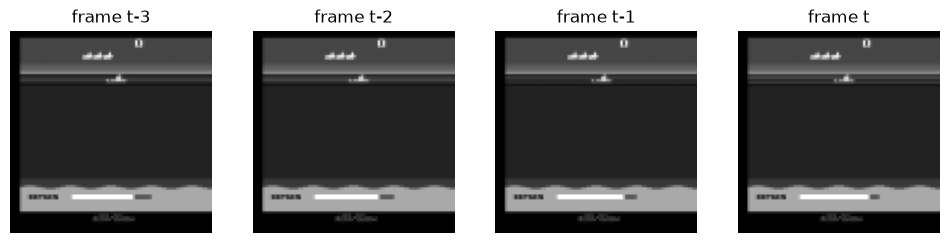

In [4]:
# show the 4 stacked frames the network sees (oldest to newest)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(obs[i], cmap="gray")
    ax.set_title(f"frame t-{3 - i}" if i < 3 else "frame t")
    ax.axis("off")
plt.show()

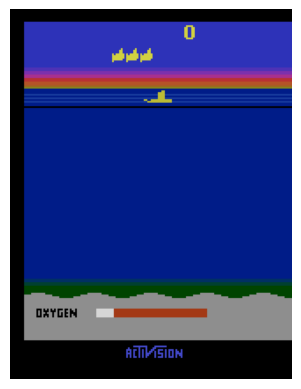

In [5]:
# for comparison: the raw full-colour frame straight from the emulator
raw_env = gym.make("SeaquestNoFrameskip-v4", render_mode="rgb_array")
raw_env.reset(seed=0)
for _ in range(20):
    raw_env.step(raw_env.action_space.sample())
plt.imshow(raw_env.render())
plt.axis("off")
plt.show()